# Predicción del puntaje global de la prueba Saber 11: preparación de datos, partición y modelos de referencia

### Andrés Giovanny Rubiano Muñoz "Andy Rubiano"

**Maestría en Inteligencia Artificial**
**Universidad de La Salle**

**Ciencia de Datos**

---

**Fase 2 del proyecto:** dejar los datos listos para modelar y medir qué tan lejos llega un modelo sencillo.

**Caso de estudio:** *Resultados únicos Saber 11*, ICFES, periodo **2022-4**, muestra representativa de **1.000 estudiantes** publicada en Kaggle ([`andyrubiano/saber-11-muestra-2022-4`](https://www.kaggle.com/datasets/andyrubiano/saber-11-muestra-2022-4), CC BY-SA 4.0).

**Qué se predice:**
*   `punt_global`, el puntaje global de 0 a 500 (un problema de **regresión**: predecir un número).
*   `nivel_desempeno`, si el estudiante queda en el tercio **bajo**, **medio** o **alto** de puntajes (un problema de **clasificación**: predecir una categoría).

**Qué deja este cuaderno:** un conjunto de datos limpio, una división fija de los estudiantes en tres grupos (entrenamiento, validación y prueba), las transformaciones necesarias para que los modelos entiendan los datos y dos modelos sencillos que sirven de vara de medida. Todo se guarda para que el cuaderno 03 trabaje exactamente sobre lo mismo.

## 1. De dónde partimos

El cuaderno 01 exploró los datos y dejó una lista de decisiones. Aquí se ponen en práctica, una por una, y cada paso explica **por qué** se hace así. La tabla sirve de mapa:

| Qué se decidió en la exploración | Por qué | Dónde se aplica |
|---|---|---|
| Revisar duplicados antes de dividir los datos | Un mismo estudiante en entrenamiento y en prueba haría trampa en la evaluación | Sección 3 |
| Sacar los cinco puntajes por área | El puntaje global se calcula con ellos: usarlos sería darle la respuesta al modelo | Sección 4.1 |
| Quitar columnas que no aportan (constantes, códigos, nombres, municipio) | No describen al estudiante o tienen demasiadas categorías para 1.000 filas | Sección 4.1 |
| Tratar los faltantes como información, no como basura | Quien no responde el cuestionario saca, en promedio, 24,6 puntos menos | Sección 4.2 |
| Conservar a los adultos, pero recortar la edad extrema | Son estudiantes reales, pero una cola de hasta 72 años desbalancea los modelos | Sección 4.3 |
| Conservar los puntajes extremos | Son resultados reales, no errores | Sección 4.3 |
| Crear variables nuevas con sentido (hacinamiento, extraedad, cuestionario incompleto) | Resumen patrones que la exploración mostró | Sección 5 |
| Agrupar estratos altos y departamentos en regiones | Con pocos estudiantes por grupo, el modelo no puede aprender nada estable | Secciones 5.2 y 5.3 |
| Niveles de desempeño por terciles y división estratificada | Tres clases del mismo tamaño en cada grupo de datos | Secciones 5.4 y 6 |
| Empezar con un modelo lineal sencillo | Es la vara que los modelos de la fase 3 tienen que superar | Sección 8 |

## 2. Preparación del entorno

Se cargan las librerías de trabajo (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `kagglehub`, `joblib`). En Google Colab ya vienen instaladas; en un computador propio se instalan con `pip install -r requirements.txt`. El cuaderno detecta si corre dentro del repositorio o en Colab y crea las carpetas donde guardará los datos procesados, los modelos y las figuras.

In [1]:
import os, sys, time, warnings, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
import seaborn as sns
import sklearn
import joblib
import kagglehub
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__, "| kagglehub:", kagglehub.__version__)

IN_COLAB = "google.colab" in sys.modules

def find_project_root(start=Path.cwd()):
    """Sube por el árbol de carpetas hasta encontrar la raíz del repositorio (README.md + notebooks/)."""
    for candidate in [start, *start.parents]:
        if (candidate / "README.md").exists() and (candidate / "notebooks").is_dir():
            return candidate
    return start

PROJECT_ROOT = Path("/content/saber11-project") if IN_COLAB else find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
FIG_DIR = PROJECT_ROOT / "assets" / "images" / "data"
for folder in (PROCESSED_DIR, MODELS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print(f"Entorno          : {'Google Colab' if IN_COLAB else 'local'}")
print(f"Raíz del proyecto: {PROJECT_ROOT}")

pandas: 3.0.6 | numpy: 2.5.4 | scikit-learn: 1.9.1 | kagglehub: 1.0.2
Entorno          : local
Raíz del proyecto: d:\Universidad de La Salle\2do semestre\Ciencia de datos\Proyecto final\saber11-project


Esta celda deja listas tres cosas: los colores de las figuras, una semilla y las funciones que califican a los modelos.

La semilla (`RANDOM_STATE = 42`): varios pasos del análisis dependen del azar, por ejemplo, decidir qué estudiantes van a entrenamiento y cuáles a prueba. La semilla es un número que fija ese azar con la misma semilla, el sorteo sale siempre igual, así cualquier persona que ejecute el cuaderno obtiene exactamente las mismas cifras.

1. Cuando se predice el puntaje (un número de 0 a 500)
*   **MAE (error absoluto medio):** cuántos puntos se equivoca el modelo, en promedio, si a un estudiante que sacó 250 le predice 280, se equivoca por 30, si a otro que sacó 200 le predice 190, se equivoca por 10. El MAE de esos dos es 20 puntos, por consiguiente, entre más bajo, mejor.
*   **RMSE (raíz del error cuadrático medio):** también se mide en puntos, pero castiga más los errores grandes, donde dos modelos con el mismo MAE de 20 pueden ser distintos, uno que se equivoca 20 y 20 tiene un RMSE de 20 y otro que acierta a uno y se equivoca 40 con el otro tiene un RMSE de 28,3. Entre más bajo, mejor y si el RMSE es mucho mayor que el MAE, hay algunos errores grandes.
*   **R² (coeficiente de determinación):** qué parte de las diferencias entre estudiantes logra explicar el modelo. Va de 0 a 1, donde 0 equivale a predecirle a todos el mismo puntaje promedio y 1 sería acertarle a todos. Un R² de 0,30 quiere decir que el modelo explica el 30 % de por qué unos estudiantes sacan más que otros.

2. Cuando se predice el nivel de desempeño (Bajo, Medio o Alto)

Para las tres medidas que siguen, imaginar 50 estudiantes que de verdad son de nivel *Alto* y un modelo que marca a 40 estudiantes como *Alto*, de los cuales 30 lo son de verdad.
*   **Exactitud:** porcentaje de estudiantes a los que el modelo les asigna el nivel correcto. Con tres niveles del mismo tamaño, adivinar al azar da alrededor de 33 %.
*   **Precisión:** de los que el modelo marca como *Alto*, cuántos lo son de verdad: 30 de 40, es decir 75 %. Responde a la pregunta "¿puedo confiar en lo que dice el modelo?".
*   **Exhaustividad.** De los que de verdad son *Alto*, a cuántos encuentra el modelo: 30 de 50, es decir 60 %. Responde a la pregunta "¿a cuántos se le escapan?".
*   **F1:** un solo número que resume la precisión y la exhaustividad, y que solo es alto si las dos lo son. En el ejemplo da 0,67. El F1 macro calcula el F1 de cada nivel (Bajo, Medio y Alto) y los promedia, de modo que los tres pesan igual. Es la medida principal para comparar clasificadores.
*   **AUC-ROC:** mide si el modelo sabe ordenar a los estudiantes. Se toma al azar un estudiante que sí es *Alto* y otro que no lo es: el AUC es la probabilidad de que el modelo le dé más probabilidad de ser *Alto* al que realmente lo es. 0,5 es lanzar una moneda y 1 es ordenar siempre bien.

In [2]:
C_BASE, C_ACCENT, C_NEU = "#2a78d6", "#eb6834", "#5B7C99"
TINTA, GRIS = "#0b0b0b", "#52514e"
PALETTE = [C_BASE, C_ACCENT, "#2CA02C", "#9467BD", "#8C564B", "#E377C2", "#7F7F7F", "#BCBD22"]
sns.set_style("whitegrid")
sns.set_palette(PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#d9d8d3", "axes.labelcolor": GRIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "grid.color": "#eeede9", "grid.linewidth": 0.8,
})
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
CLASES = ["Bajo", "Medio", "Alto"]

def save_fig(fig, name):
    """Guarda la figura en assets/images/data/<name>.png."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"Figura guardada: {path.relative_to(PROJECT_ROOT) if path.is_relative_to(PROJECT_ROOT) else path}")

def evaluar_regresion(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": root_mean_squared_error(y_true, y_pred), "R2": r2_score(y_true, y_pred)}

def evaluar_clasificacion(y_true, y_pred, proba=None):
    out = {"exactitud": accuracy_score(y_true, y_pred),
           "precisión macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
           "exhaustividad macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
           "F1 macro": f1_score(y_true, y_pred, average="macro", zero_division=0)}
    if proba is not None:
        out["AUC-ROC (ovr)"] = roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=sorted(CLASES))
    return out

## 3. Carga de la muestra y control de duplicados

Se descargan los 1.000 estudiantes desde Kaggle y se confirma que nadie aparece dos veces.

La muestra se descarga de la misma fuente que en el cuaderno anterior, si Kaggle no está disponible el cuaderno puede reconstruirla a partir de la población completa, usando la misma semilla para obtener exactamente los mismos registros.

Antes de continuar, se revisan los duplicados. En los datos originales del ICFES cada registro aparece dos veces, por ende, si el mismo estudiante quedara tanto en el conjunto de entrenamiento como en el de evaluación, el modelo podría reconocerlo y las métricas parecerían mejores de lo que realmente son.

In [3]:
KAGGLE_MUESTRA = "andyrubiano/saber-11-muestra-2022-4"
KAGGLE_POBLACION = "andyrubiano/saber-11-resultados-2022-4"
CSV_MUESTRA, N_MUESTRA, SEMILLA_MUESTRA = "saber11_muestra_1000.csv", 1000, 42
SCORE_COLS = ["punt_matematicas", "punt_lectura_critica", "punt_sociales_ciudadanas", "punt_c_naturales", "punt_ingles", "punt_global"]
ID_COLS = ["estu_consecutivo", "estu_fechanacimiento"]

def muestrear_poblacion():
    """Respaldo determinista: reconstruye la misma muestra desde la población completa en Kaggle."""
    pob = pd.read_parquet(kagglehub.dataset_download(KAGGLE_POBLACION, path="saber11_20224.parquet"))
    pob = pob.drop_duplicates().sort_values("estu_consecutivo").reset_index(drop=True)
    estrato = (pob["cole_naturaleza"].astype(object).fillna("NA") + "|" + pob["cole_area_ubicacion"].astype(object).fillna("NA")
               + "|" + pd.qcut(pob["punt_global"], 3, labels=["T1", "T2", "T3"]).astype(str)).to_numpy()
    conteo = pd.Series(estrato).value_counts().sort_index()
    cuota = conteo / conteo.sum() * N_MUESTRA
    base = np.floor(cuota).astype(int)
    base[(cuota - base).sort_values(ascending=False).index[:N_MUESTRA - base.sum()]] += 1
    rs = np.random.RandomState(SEMILLA_MUESTRA)
    elegidos = []
    for clave, k in base.items():
        elegidos.extend(rs.choice(np.flatnonzero(estrato == clave), size=int(k), replace=False))
    m = pob.iloc[sorted(elegidos)].reset_index(drop=True)
    for c in m.columns:
        if str(m[c].dtype) == "category":
            m[c] = m[c].astype(object)
    for c in SCORE_COLS:
        m[c] = m[c].astype("Int64")
    return m.astype({c: "string" for c in m.columns if c not in SCORE_COLS})

t0 = time.time()
try:
    df = pd.read_csv(kagglehub.dataset_download(KAGGLE_MUESTRA, path=CSV_MUESTRA), dtype=str)
    FUENTE = f"Kaggle · {KAGGLE_MUESTRA} · {CSV_MUESTRA}"
except Exception as error:
    print(f"Muestra publicada no disponible ({type(error).__name__}); se reconstruye desde la población con la misma semilla.")
    df = muestrear_poblacion().astype(str).replace({"<NA>": np.nan, "nan": np.nan})
    FUENTE = f"Kaggle · {KAGGLE_POBLACION} · muestreo determinista (semilla {SEMILLA_MUESTRA})"
for c in SCORE_COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("float32")

n_cargadas = len(df)
df = df.drop_duplicates().reset_index(drop=True)
assert len(df) == N_MUESTRA and df["estu_consecutivo"].is_unique
print(f"Fuente   : {FUENTE}")
print(f"Origen   : ICFES · datos.gov.co, conjunto kgxf-xxbe, periodo 2022-4 (CC BY-SA 4.0)")
print(f"Registros: {n_cargadas:,} cargados · {len(df):,} tras el control de duplicados · {df.shape[1]} columnas · {time.time() - t0:.1f} s")

Fuente   : Kaggle · andyrubiano/saber-11-muestra-2022-4 · saber11_muestra_1000.csv
Origen   : ICFES · datos.gov.co, conjunto kgxf-xxbe, periodo 2022-4 (CC BY-SA 4.0)
Registros: 1,000 cargados · 1,000 tras el control de duplicados · 51 columnas · 1.4 s


La muestra contiene los 1.000 estudiantes previstos y sus 51 columnas, sin registros duplicados, como se esperaba al extraerla de la población depurada, aun así, el cuaderno conserva este control para aplicarlo a otros periodos o a la población completa, donde cada estudiante aparece dos veces y los duplicados deben eliminarse antes de continuar.

## 4. Limpieza de datos

### 4.1 Columnas que salen del conjunto

*   **Variables que causarían fuga de información**: los cinco puntajes por área y el nivel de inglés. Como el puntaje global se calcula a partir de ellos, incluirlos permitiría predecirlo sin que el modelo tuviera que aprender sobre las características del estudiante, no obstante, se conservan aparte para agrupar estudiantes en la fase 3, donde no se predice el puntaje.
*   **Variables con poca variación**: el periodo, el estado del estudiante, la condición de privación de la libertad, el calendario escolar (997 de 1.000 estudiantes pertenecen al calendario A) y el bilingüismo (solo cinco colegios son bilingües). Al ser casi iguales para todos, aportan poca información al modelo.
*   **Códigos y nombres identificadores**: los códigos DANE e ICFES y los nombres de colegios y sedes identifican instituciones, pero no describen a los estudiantes. En la muestra hay más de 880 colegios distintos para 1.000 estudiantes.
*   **Ubicación demasiado específica**: el municipio tiene 332 valores distintos en una muestra de 1.000 estudiantes, por lo que muchas categorías tendrían un solo caso, en su lugar se usan regiones, como se explica en la sección 5.3.
*   **Variables redundantes o poco informativas**: el lugar de residencia y el de presentación de la prueba repiten la ubicación del colegio, la nacionalidad casi no varía y el tipo de documento refleja principalmente la edad.

El código del estudiante se conserva como índice para identificar cada fila, pero no se incluye entre las variables del modelo.

In [4]:
TARGET = "punt_global"
AREA_COLS = ["punt_lectura_critica", "punt_matematicas", "punt_sociales_ciudadanas", "punt_c_naturales", "punt_ingles"]
LEAK_COLS = AREA_COLS + ["desemp_ingles"]
CONST_COLS = ["periodo", "estu_estudiante", "estu_estadoinvestigacion", "estu_privado_libertad", "cole_calendario", "cole_bilingue"]
ID_LIKE = ["cole_cod_dane_establecimiento", "cole_cod_dane_sede", "cole_codigo_icfes", "cole_nombre_establecimiento",
           "cole_nombre_sede", "cole_cod_depto_ubicacion", "cole_cod_mcpio_ubicacion", "cole_mcpio_ubicacion"]
REDUNDANT = ["estu_cod_depto_presentacion", "estu_cod_mcpio_presentacion", "estu_depto_presentacion", "estu_mcpio_presentacion",
             "estu_cod_reside_depto", "estu_cod_reside_mcpio", "estu_depto_reside", "estu_mcpio_reside",
             "estu_nacionalidad", "estu_pais_reside", "estu_tipodocumento"]

df = df.set_index("estu_consecutivo")
areas = df[AREA_COLS].copy()          # se conservan aparte para el clustering de la fase 3
df = df.drop(columns=LEAK_COLS + CONST_COLS + ID_LIKE + REDUNDANT)
print(f"Columnas descartadas: {len(LEAK_COLS + CONST_COLS + ID_LIKE + REDUNDANT)} · conservadas: {df.shape[1]} → {df.columns.tolist()}")

Columnas descartadas: 31 · conservadas: 19 → ['cole_area_ubicacion', 'cole_caracter', 'cole_depto_ubicacion', 'cole_genero', 'cole_jornada', 'cole_naturaleza', 'cole_sede_principal', 'estu_fechanacimiento', 'estu_genero', 'fami_cuartoshogar', 'fami_educacionmadre', 'fami_educacionpadre', 'fami_estratovivienda', 'fami_personashogar', 'fami_tieneautomovil', 'fami_tienecomputador', 'fami_tieneinternet', 'fami_tienelavadora', 'punt_global']


Al finalizar la depuración, se conservan 19 de las 31 columnas iniciales. Estas variables reúnen la información disponible sobre el estudiante antes de presentar la prueba:,siete relacionadas con el colegio, nueve con el hogar, la fecha de nacimiento y el género, el puntaje global se mantiene como variable objetivo para el análisis y por su parte, los cinco puntajes por área se guardan por separado, ya que se utilizarán en la fase 3 para segmentar los resultados.

### 4.2 Valores faltantes: por qué faltan y qué se hace con ellos


La exploración mostró que las respuestas faltantes no aparecen de manera aleatoria, quienes dejan incompleto el cuestionario del hogar obtienen, en promedio, 24,6 puntos menos, además, la falta de respuestas es más frecuente en ciertas jornadas y departamentos sugiriendo que la ausencia de información también aporta contexto sobre los estudiantes y que eliminarla sin más podría sesgar el análisis, por esa razón no se eliminan las filas incompletas y hacerlo descartaría al 11 % de la muestra y afectaría especialmente a estudiantes con puntajes más bajos, el modelo terminaría aprendiendo a partir de una muestra menos representativa y más favorecida que la población que se busca describir, tampoco se reemplazan todas las respuestas faltantes por un promedio, eso ocultaría el hecho de que el estudiante no respondió, una señal potencialmente informativa. En su lugar, se conserva explícitamente la ausencia de respuesta. 

En las preguntas sobre el hogar, los valores vacíos se registran como *No respondió* para la variable sobre el carácter del colegio, se utiliza *No reportado*, además, se crea la variable `cuestionario_incompleto`, que toma el valor 1 cuando falta al menos una respuesta del hogar.

Algunas variables numéricas derivadas como la educación de los padres o el número de personas por cuarto requieren valores numéricos para poder incorporarse al modelo. En esos casos, los valores faltantes se imputan dentro del proceso de modelado, utilizando únicamente la información del dataset de entrenamiento y cada imputación se acompaña de una variable indicadora que registra si el dato original estaba ausente conservando tanto un valor utilizable por el modelo como la señal de que faltaba información.

In [5]:
FAMI_COLS = [c for c in df.columns if c.startswith("fami_")]
df["cuestionario_incompleto"] = df[FAMI_COLS].isna().any(axis=1).astype("int8")
for col in FAMI_COLS:
    df[col] = df[col].fillna("No respondió")
df["cole_caracter"] = df["cole_caracter"].fillna("No reportado")
restantes = df.columns[df.isna().any()].tolist()
print(f"Cuestionario incompleto: {df['cuestionario_incompleto'].sum()} estudiantes ({df['cuestionario_incompleto'].mean() * 100:.1f} %)")
print(f"Columnas con faltantes tras el tratamiento: {restantes if restantes else 'ninguna'}")

Cuestionario incompleto: 112 estudiantes (11.2 %)
Columnas con faltantes tras el tratamiento: ninguna


De los estudiantes analizados 112 (11,2 %) dejaron incompleto el cuestionario del hogar, una proporción consistente con la observada durante la exploración. Al reemplazar las respuestas vacías por *No respondió*, se conserva esa información y ninguna columna queda con valores faltantes, además, como estos estudiantes obtienen en promedio 24,6 puntos menos, la categoría permite que el modelo aproveche esa señal en lugar de perderla al eliminar sus registros o imputar las respuestas sin distinguirlas.

### 4.3 Valores atípicos: se recorta la edad y se conservan los puntajes

En los puntajes se detectan muy pocos valores extremos, solo aparece un puntaje global atípico, de 412 puntos, la revisión indica que corresponde a un estudiante real con un resultado excepcional, no a un error de digitación por eso se conserva, ya que eliminarlo ocultaría un caso que puede aportar información valiosa.

Con la edad, la decisión es distinta, el 4,5 % de los estudiantes son adultos de jornadas nocturnas o sabatinas con edades de hasta 72,5 años. Estos registros también son válidos, pero unos pocos valores tan alejados pueden influir demasiado en los modelos lineales y dificultar el escalado de la variable, por ende, para limitar ese efecto sin excluir a los estudiantes adultos, se aplica una winsorización en el percentil 99, donde las edades que superan ese umbral se ajustan a 35 años y así, permanecen en el conjunto de datos y se conserva el orden relativo de las edades, pero su influencia en el modelo queda acotada.

También se evaluó transformar la edad con un logaritmo, lo que reduce la influencia de los valores altos, sin embargo, se mantuvo la escala en años porque resulta más fácil de interpretar, cabe resaltar que la variable extraedad que identifica a quienes tienen 19 años o más ya recoge el cambio en el patrón de puntaje asociado con ser mayor.

In [6]:
FECHA_PRUEBA = pd.Timestamp("2022-09-04")
fecha_nac = pd.to_datetime(df["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce")
df["edad"] = ((FECHA_PRUEBA - fecha_nac).dt.days / 365.25).round(1)
assert df["edad"].between(13, 80).all()
P99 = float(df["edad"].quantile(0.99))
df["edad_original"] = df["edad"]
df["edad"] = df["edad"].clip(upper=P99)
df["extraedad"] = (df["edad_original"] >= 19).astype("int8")
df = df.drop(columns=["estu_fechanacimiento"])

q1, q3 = df[TARGET].quantile([0.25, 0.75]); iqr = q3 - q1
atipicos_punt = ((df[TARGET] < q1 - 1.5 * iqr) | (df[TARGET] > q3 + 1.5 * iqr)).sum()
resumen = pd.DataFrame({"edad original": df["edad_original"].describe(), "edad winsorizada (p99)": df["edad"].describe()}).round(1)
resumen.loc["asimetría"] = [df["edad_original"].skew(), df["edad"].skew()]
print(f"Percentil 99 de la edad: {P99:.1f} años · estudiantes recortados: {(df['edad_original'] > P99).sum()} · extraedad (≥ 19): {df['extraedad'].sum()}")
print(f"Atípicos del puntaje global por la regla IQR: {atipicos_punt} → se conservan")
display(resumen.round(2).T)

Percentil 99 de la edad: 35.0 años · estudiantes recortados: 10 · extraedad (≥ 19): 112
Atípicos del puntaje global por la regla IQR: 1 → se conservan


,count,mean,std,min,25%,50%,75%,max,asimetría
edad original,"1,000.000",17.900,3.600,15.100,16.700,17.200,18.100,72.500,8.170
edad winsorizada (p99),"1,000.000",17.800,2.500,15.100,16.700,17.200,18.100,35.000,5.130


El percentil 99 de la edad es de 35 años, de modo que el recorte solo afecta a 10 estudiantes, los que tenían entre 35 y 72,5 años. La edad típica no cambia, pues la mediana sigue en 17,2 años, pero la cola se acorta y la desviación baja de 3,6 a 2,5 años, mientras que la variable de extraedad marca a 112 estudiantes de 19 años o más. En el puntaje global solo hay un valor atípico, el de 412 puntos y se deja tal como está, porque es un resultado real y entender los extremos hace parte del objetivo del proyecto.

## 5. Ingeniería de variables

En esta parte se traducen las respuestas del cuestionario a números que el modelo pueda usar y se construyen algunas variables nuevas a partir de lo que mostró la exploración.

### 5.1 Variables ordinales y derivadas

La educación de la madre y del padre se codifica en una escala ordinal de 0 a 9, desde *Ninguno* hasta *Postgrado*, conservando el orden natural de los niveles educativos. Las respuestas *No sabe*, *No aplica* y *No respondió* no corresponden a un nivel de esa escala, por lo que se dejan vacías en la variable numérica y se registran por separado mediante `educ_madre_desconocida` y `educ_padre_desconocida`, así el modelo puede distinguir la falta de información de los distintos niveles educativos.

También se construye la variable personas por cuarto, un indicador de hacinamiento que se calcula dividiendo el número de personas del hogar por la cantidad de cuartos destinados a dormir. Como el cuestionario registra el número de personas mediante rangos, se usa el punto medio de cada intervalo, por ejemplo, *1 a 2* se representa como 1,5 y *9 o más* como 9,5. La exploración mostró que los puntajes tienden a bajar a medida que aumenta el tamaño del hogar, mientras que la relación con el número de cuartos es menos directa, la razón entre ambas medidas resume esa información en una sola variable.

Por último, se incorporan extraedad, que identifica a quienes tienen 19 años o más (sección 4.3) y cuestionario incompleto, que señala si falta al menos una respuesta del hogar (sección 4.2). El género del estudiante se representa con los valores 0 y 1.

In [7]:
EDU_NIVEL = {"Ninguno": 0, "Primaria incompleta": 1, "Primaria completa": 2, "Secundaria (Bachillerato) incompleta": 3,
             "Secundaria (Bachillerato) completa": 4, "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
             "Educación profesional incompleta": 7, "Educación profesional completa": 8, "Postgrado": 9}
PERSONAS_MEDIO = {"1 a 2": 1.5, "3 a 4": 3.5, "5 a 6": 5.5, "7 a 8": 7.5, "9 o más": 9.5}
CUARTOS_MEDIO = {"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o mas": 6}

for p, col in [("madre", "fami_educacionmadre"), ("padre", "fami_educacionpadre")]:
    ordinal = df[col].map(EDU_NIVEL)
    df[f"educ_{p}_ord"] = ordinal.astype("float32")
    df[f"educ_{p}_desconocida"] = ordinal.isna().astype("int8")
df["personas_por_cuarto"] = (df["fami_personashogar"].map(PERSONAS_MEDIO) / df["fami_cuartoshogar"].map(CUARTOS_MEDIO)).astype("float32")
df["genero_F"] = (df["estu_genero"] == "F").astype("int8")
df = df.drop(columns=["estu_genero", "fami_educacionmadre", "fami_educacionpadre"])

print("Educación de la madre (0 a 9): nivel desconocido en", f"{df['educ_madre_desconocida'].mean() * 100:.1f} % · padre {df['educ_padre_desconocida'].mean() * 100:.1f} %")
display(df[["educ_madre_ord", "educ_padre_ord", "personas_por_cuarto", "edad"]].describe().round(2).T)

Educación de la madre (0 a 9): nivel desconocido en 9.3 % · padre 14.5 %


,count,mean,std,min,25%,50%,75%,max
educ_madre_ord,907.000,4.170,2.300,0.000,3.000,4.000,6.000,9.000
educ_padre_ord,855.000,3.710,2.300,0.000,2.000,4.000,4.000,9.000
personas_por_cuarto,953.000,1.720,0.830,0.380,1.170,1.750,1.830,7.500
edad,"1,000.000",17.780,2.490,15.100,16.700,17.200,18.100,35.000


La educación de la madre se conoce para 907 estudiantes y la del padre para 855, es decir, falta en el 9,3 % y en el 14,5 % de los casos, una diferencia que tiene una explicación natural en los hogares donde el padre no está presente y que las columnas indicadoras conservan. En ambos casos el valor más típico es 4, que corresponde a secundaria completa y en cuanto al hacinamiento, lo usual es 1,75 personas por cuarto, con un máximo de 7,5.

### 5.2 Categorías: estrato agrupado y cruce entre naturaleza y zona del colegio

El estrato se mantiene como categoría, pero los estratos 4, 5 y 6 se juntan en uno solo porque en la muestra apenas tienen 55, 16 y 11 estudiantes, muy pocos para que el modelo aprenda algo confiable de cada uno por separado. Las variables del colegio, es decir, la naturaleza oficial o privada, la zona urbana o rural, la jornada, el carácter, el género del colegio y si se trata de la sede principal, también quedan como categorías, además, se crea una variable que cruza la naturaleza con la zona del colegio y que tiene cuatro combinaciones, oficial urbano, oficial rural, privado urbano y privado rural, ya que en los colegios oficiales los rurales obtienen menores puntajes, mientras que en los privados ocurre lo contrario y un modelo lineal, que analiza cada variable por separado, no tiene forma de descubrir ese cambio por sí mismo, así que se le entrega ya construido.

In [8]:
df["fami_estratovivienda"] = df["fami_estratovivienda"].replace({"Estrato 4": "Estrato 4 a 6", "Estrato 5": "Estrato 4 a 6", "Estrato 6": "Estrato 4 a 6"})
df["naturaleza_area"] = df["cole_naturaleza"] + " · " + df["cole_area_ubicacion"]
print("Estrato agrupado:", df["fami_estratovivienda"].value_counts().to_dict())
print("Naturaleza × área:", df["naturaleza_area"].value_counts().to_dict())

Estrato agrupado: {'Estrato 2': 347, 'Estrato 1': 258, 'Estrato 3': 204, 'Estrato 4 a 6': 82, 'No respondió': 81, 'Sin Estrato': 28}
Naturaleza × área: {'OFICIAL · URBANO': 613, 'NO OFICIAL · URBANO': 216, 'OFICIAL · RURAL': 161, 'NO OFICIAL · RURAL': 10}


Al agrupar los estratos altos, la variable queda distribuida en seis grupos con tamaños razonables, estrato 2 reúne 347 estudiantes, estrato 1, 258, estrato 3, 204, los estratos 4 a 6, 82, *No respondió*, 81 y *Sin estrato*, 28, sin esta agrupación, los estratos 5 y 6 tendrían apenas 16 y 11 estudiantes, respectivamente, lo que dejaría muy poca información para estimar su efecto por separado.

En el cruce entre naturaleza y zona del colegio, la categoría más pequeña es privado rural, con 10 estudiantes y se conserva porque, dentro de la población analizada, presenta el puntaje más alto. Durante el entrenamiento, si esta categoría queda representada por menos de cinco estudiantes, el preprocesador la agrupará con las demás categorías poco frecuentes.

### 5.3 Departamentos agrupados en regiones

Con una muestra de 1.000 estudiantes, 12 de los 32 departamentos presentes tienen menos de 15 casos., por ende, estimar un efecto independiente para departamentos con apenas dos o tres estudiantes sería poco fiable, el modelo podría terminar ajustándose a esos casos particulares en lugar de captar un patrón general.

Para contar con grupos más representativos, los departamentos se agrupan en seis regiones con sentido geográfico y educativo, Bogotá, Andina, Caribe, Pacífica, Orinoquía y Amazonía. Bogotá se mantiene como grupo independiente porque reúne 138 estudiantes y presenta uno de los puntajes promedio más altos. La celda comprueba el tamaño de cada región y presenta su puntaje promedio para mostrar cómo queda la distribución.

In [9]:
REGION = {
    "BOGOTÁ": "Bogotá",
    **{d: "Andina" for d in ["ANTIOQUIA", "BOYACA", "CALDAS", "CUNDINAMARCA", "HUILA", "NORTE SANTANDER", "QUINDIO", "RISARALDA", "SANTANDER", "TOLIMA"]},
    **{d: "Caribe" for d in ["ATLANTICO", "BOLIVAR", "CESAR", "CORDOBA", "LA GUAJIRA", "MAGDALENA", "SUCRE", "SAN ANDRES"]},
    **{d: "Pacífica" for d in ["CAUCA", "CHOCO", "NARIÑO", "VALLE"]},
    **{d: "Orinoquía" for d in ["ARAUCA", "CASANARE", "META", "VICHADA"]},
    **{d: "Amazonía" for d in ["AMAZONAS", "CAQUETA", "GUAINIA", "GUAVIARE", "PUTUMAYO", "VAUPES"]},
}
df["region"] = df["cole_depto_ubicacion"].map(REGION)
assert df["region"].notna().all(), set(df.loc[df["region"].isna(), "cole_depto_ubicacion"])
df = df.drop(columns=["cole_depto_ubicacion"])
display(df.groupby("region")[TARGET].agg(estudiantes="size", media="mean", desviacion="std").round(1).sort_values("media", ascending=False).T)

region,Bogotá,Andina,Orinoquía,Amazonía,Pacífica,Caribe
estudiantes,138.000,435.000,45.000,19.000,123.000,240.000
media,266.000,256.100,247.100,239.100,237.900,233.900
desviacion,47.000,52.100,46.600,52.700,48.300,45.900


Las seis regiones van desde 19 estudiantes en la Amazonía hasta 435 en la región Andina y mantienen el mismo orden que tienen en la población, Bogotá con 266,0 puntos, Andina con 256,1, Orinoquía con 247,1, Amazonía con 239,1, Pacífica con 237,9 y Caribe con 233,9, de modo que entre Bogotá y el Caribe hay una diferencia de 32 puntos, perdiendo el detalle por departamento, pero a cambio se obtiene una variable que el modelo sí puede aprender con 1.000 estudiantes.

### 5.4 Niveles de desempeño y lista final de variables

El nivel de desempeño se construye dividiendo los puntajes en tres partes iguales, de modo que el tercio con los puntajes más bajos corresponde al nivel *Bajo*, el del medio al nivel *Medio* y el de los puntajes más altos al nivel *Alto*, por lo tanto, las tres clases quedan del mismo tamaño y no hace falta ninguna técnica para equilibrarlas y como el nivel se calcula únicamente con el puntaje global, no se filtra ningún puntaje por área.

Con esto queda definida la lista de variables que verán los modelos, organizadas según la transformación que recibirán en el preprocesador, las numéricas, que son la edad, la educación de los padres y las personas por cuarto, las binarias, que son la extraedad, el cuestionario incompleto, la educación desconocida y el género y las categóricas, que incluyen el estrato, el tamaño del hogar, los bienes, las variables del colegio, el cruce entre naturaleza y zona y la región.

In [10]:
cortes = df[TARGET].quantile([1 / 3, 2 / 3]).to_numpy()
df["nivel_desempeno"] = pd.cut(df[TARGET], bins=[-np.inf, cortes[0], cortes[1], np.inf], labels=CLASES).astype(str)
CORTES_NIVEL = {"bajo_hasta": float(cortes[0]), "medio_hasta": float(cortes[1])}

NUM_COLS = ["edad", "educ_madre_ord", "educ_padre_ord", "personas_por_cuarto"]
BIN_COLS = ["extraedad", "cuestionario_incompleto", "educ_madre_desconocida", "educ_padre_desconocida", "genero_F"]
NOM_COLS = ["fami_estratovivienda", "fami_personashogar", "fami_cuartoshogar", "fami_tieneinternet", "fami_tienecomputador",
            "fami_tieneautomovil", "fami_tienelavadora", "cole_naturaleza", "cole_area_ubicacion", "naturaleza_area",
            "cole_jornada", "cole_caracter", "cole_genero", "cole_sede_principal", "region"]
FEATURES = NUM_COLS + BIN_COLS + NOM_COLS
sobran = set(df.columns) - set(FEATURES) - {TARGET, "nivel_desempeno", "edad_original"}
assert not sobran, sobran

print(f"Nivel de desempeño: Bajo ≤ {cortes[0]:.0f} < Medio ≤ {cortes[1]:.0f} < Alto →", df["nivel_desempeno"].value_counts().to_dict())
print(f"Variables explicativas: {len(FEATURES)} ({len(NUM_COLS)} numéricas, {len(BIN_COLS)} binarias, {len(NOM_COLS)} nominales con "
      f"{sum(df[c].nunique() for c in NOM_COLS)} niveles en total)")

Nivel de desempeño: Bajo ≤ 222 < Medio ≤ 273 < Alto → {'Bajo': 335, 'Medio': 335, 'Alto': 330}
Variables explicativas: 24 (4 numéricas, 5 binarias, 15 nominales con 61 niveles en total)


Los tercios quedan separados en 222 y 273 puntos, así que hasta 222 se considera nivel *Bajo*, hasta 273 nivel *Medio* y de ahí en adelante nivel *Alto*, con 335, 335 y 330 estudiantes respectivamente, es decir, tres clases equilibradas. La lista final queda con 24 variables explicativas, 4 numéricas, 5 binarias y 15 categóricas que en total suman 61 opciones.

### 5.5 ¿Con qué se rellenan los datos faltantes?

Para decidir cómo rellenar los vacíos de las variables numéricas se comparan tres alternativas, eliminar las filas que tengan algún vacío, rellenar con la mediana y marcar el vacío en una columna aparte o rellenar con el valor de los cinco estudiantes más parecidos (`KNNImputer`) y marcar igualmente el vacío. Las tres se evalúan con el mismo modelo lineal y con validación cruzada, que consiste en partir el conjunto en cinco partes, entrenar con cuatro y medir el error en la que queda por fuera, rotando hasta que cada parte haya servido una vez de prueba y el procedimiento se repite tres veces con particiones distintas, de modo que cada alternativa se mide quince veces y el resultado no depende de una sola división afortunada.

La regla de decisión se fija antes de ver los resultados, gana la alternativa con menor error pero si la mediana y los vecinos quedan prácticamente empatados se prefiere la mediana, que es más sencilla y más estable cuando hay pocos datos.

In [11]:
def preprocesador_lineal(imputador):
    return ColumnTransformer([
        ("num", Pipeline([("imp", imputador), ("sc", StandardScaler())]), NUM_COLS),
        ("bin", "passthrough", BIN_COLS),
        ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=5, dtype=np.float32), NOM_COLS),
    ], verbose_feature_names_out=False)

X_all, y_all = df[FEATURES], df[TARGET]
cv_rep = [KFold(n_splits=5, shuffle=True, random_state=s) for s in (0, 1, 2)]
def mae_cv(pipe, X, y):
    return np.concatenate([-cross_val_score(pipe, X, y, cv=cv, scoring="neg_mean_absolute_error") for cv in cv_rep])

estrategias = {}
completas = X_all[NUM_COLS].notna().all(axis=1)
estrategias["Eliminar filas incompletas"] = (mae_cv(Pipeline([("prep", preprocesador_lineal(SimpleImputer(strategy="median"))), ("m", Ridge(alpha=1.0))]),
                                                    X_all[completas], y_all[completas]), int(completas.sum()))
estrategias["Mediana + indicadores"] = (mae_cv(Pipeline([("prep", preprocesador_lineal(SimpleImputer(strategy="median"))), ("m", Ridge(alpha=1.0))]), X_all, y_all), len(X_all))
estrategias["KNN (5 vecinos) + indicadores"] = (mae_cv(Pipeline([("prep", preprocesador_lineal(KNNImputer(n_neighbors=5))), ("m", Ridge(alpha=1.0))]), X_all, y_all), len(X_all))
comparacion = pd.DataFrame({k: {"filas usadas": n, "MAE medio": v.mean(), "desviación entre pliegues": v.std(), "MAE mínimo": v.min(), "MAE máximo": v.max()}
                            for k, (v, n) in estrategias.items()}).T
display(comparacion.round(2))
IMPUTADOR = "median"
print("Imputador elegido para las ordinales: mediana (ajustada solo con entrenamiento) + indicadores de faltante")

,filas usadas,MAE medio,desviación entre pliegues,MAE mínimo,MAE máximo
Eliminar filas incompletas,817.000,35.730,1.610,33.190,38.790
Mediana + indicadores,"1,000.000",35.530,1.350,32.930,38.420
KNN (5 vecinos) + indicadores,"1,000.000",35.570,1.400,32.810,38.540


Imputador elegido para las ordinales: mediana (ajustada solo con entrenamiento) + indicadores de faltante


Las tres estrategias ofrecen resultados muy similares: el error promedio es de 35,53 puntos con la mediana, 35,57 con la imputación por vecinos y 35,73 al eliminar las filas incompletas. La diferencia entre alternativas es pequeña frente a la variación entre repeticiones de la validación, donde el error cambia entre 1,35 y 1,61 puntos, en otras palabras, esa variación es unas diez veces mayor que la distancia entre los resultados promedio.

Eliminar filas queda ligeramente por detrás tiene un costo importante que el error por sí solo no refleja ya que se perderían 183 estudiantes, el 18 % de la muestra. Dado que los valores faltantes no ocurren al azar, esta exclusión afectaría sobre todo a estudiantes con puntajes más bajos.

La imputación por vecinos tampoco ofrece una mejora relevante frente a la mediana, las columnas indicadoras ya informan al modelo cuándo faltaba un dato, que es la señal más importante en este caso, por tal motivo, se elige la mediana siendo una opción más sencilla, reproducible y adecuada para el tamaño disponible de entrenamiento, de 700 estudiantes.

## 6. División en entrenamiento, validación y prueba

Los 1.000 estudiantes se dividen en tres grupos para que, al final, el modelo se evalúe con personas que nunca vio durante su aprendizaje. El grupo de entrenamiento, con 700 estudiantes, es con el que el modelo aprende, el de validación, con 150, sirve para comparar modelos y ajustes sin tocar la prueba y el de prueba, con los 150 restantes, se usa una sola vez al final para reportar una cifra honesta de qué tan bien predice el modelo.

La división es estratificada por nivel de desempeño, lo que garantiza que cada grupo tenga la misma proporción de estudiantes de nivel bajo, medio y alto y con ello, una distribución de puntajes muy parecida. La semilla fija hace que la división sea siempre la misma y se guarda para que el cuaderno 03 trabaje exactamente con los mismos estudiantes, mientras que la figura permite comprobar que los tres grupos se parecen.

,train,val,test
estudiantes,700.000,150.000,150.000
media puntaje,249.400,248.600,248.800
desviación,50.600,49.500,51.400
mediana,244.500,248.500,242.500
% Bajo,33.400,34.000,33.300
% Medio,33.600,33.300,33.300
% Alto,33.000,32.700,33.300


Figura guardada: assets\images\data\split_check.png


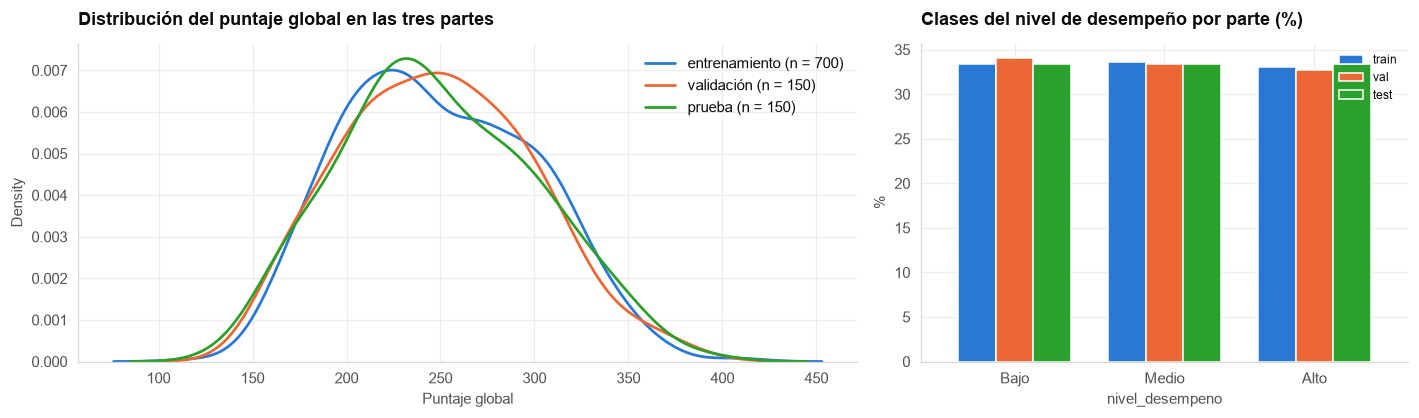

In [12]:
posiciones = np.arange(len(df))
estrato_split = df["nivel_desempeno"].to_numpy()
pos_train, pos_temp = train_test_split(posiciones, test_size=0.30, random_state=RANDOM_STATE, stratify=estrato_split)
pos_val, pos_test = train_test_split(pos_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=estrato_split[pos_temp])
particion = pd.Series("train", index=df.index, name="particion")
particion.iloc[pos_val] = "val"; particion.iloc[pos_test] = "test"

partes = {p: (df.loc[particion == p, FEATURES], df.loc[particion == p, TARGET], df.loc[particion == p, "nivel_desempeno"]) for p in ["train", "val", "test"]}
X_train, y_train, c_train = partes["train"]; X_val, y_val, c_val = partes["val"]; X_test, y_test, c_test = partes["test"]
assert not (set(X_train.index) & set(X_val.index)) and not (set(X_train.index) & set(X_test.index)) and not (set(X_val.index) & set(X_test.index))

control = pd.DataFrame({p: {"estudiantes": len(y), "media puntaje": y.mean(), "desviación": y.std(), "mediana": y.median(),
                            **{f"% {k}": (c == k).mean() * 100 for k in CLASES}} for p, (X, y, c) in partes.items()}).round(1)
display(control)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.6, 1]})
for nombre, (X, y, c), color in zip(["entrenamiento", "validación", "prueba"], partes.values(), [C_BASE, C_ACCENT, "#2CA02C"]):
    sns.kdeplot(y, ax=axes[0], color=color, linewidth=1.8, label=f"{nombre} (n = {len(y)})")
axes[0].set_title("Distribución del puntaje global en las tres partes"); axes[0].set_xlabel("Puntaje global"); axes[0].legend(frameon=False)
tabla = pd.DataFrame({p: c.value_counts(normalize=True).reindex(CLASES) * 100 for p, (X, y, c) in partes.items()})
tabla.plot(kind="bar", ax=axes[1], color=[C_BASE, C_ACCENT, "#2CA02C"], width=0.75)
axes[1].set_title("Clases del nivel de desempeño por parte (%)"); axes[1].set_ylabel("%"); axes[1].legend(frameon=False, fontsize=8); axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout(); save_fig(fig, "split_check"); plt.show()

Los grupos quedan con 700, 150 y 150 estudiantes, sin que nadie aparezca en dos de ellos a la vez, algo que el código verifica explícitamente.

Las tres particiones tienen distribuciones similares, entre el 33 % y el 34 % de los estudiantes se encuentra en cada nivel y los puntajes promedio son cercanos, 249,4 en entrenamiento, 248,6 en validación y 248,8 en prueba. En la figura, las curvas casi se superponen y la de validación se concentra ligeramente más alrededor del centro. Esa diferencia es esperable con solo 150 estudiantes y ayuda a entender por qué las métricas de validación y prueba no serán idénticas.

## 7. Transformar los datos sin fuga de información

Rellenar vacíos con la mediana, llevar las variables a una misma escala o convertir las categorías en columnas son pasos que aprenden algo de los datos y si ese aprendizaje incluyera a los estudiantes de prueba, el modelo estaría viendo de antemano información del examen con el que se le va a calificar, algo que se conoce como fuga de información, para evitarlo, todos esos pasos se agrupan en un preprocesador (`ColumnTransformer`) que se ajusta únicamente con los 700 estudiantes de entrenamiento y que luego se aplica, sin volver a ajustarse, a los grupos de validación y prueba.

Se construyen dos versiones porque no todos los modelos necesitan lo mismo. La primera, `prep_lineal`, es para los modelos sensibles a la escala de las variables, como la regresión lineal y la logística, la SVM, el KNN y la red neuronal, y en ella las variables numéricas se estandarizan, es decir, se dejan con promedio 0 y desviación 1 para que la edad en años y la educación en una escala de 0 a 9 pesen de forma pareja, mientras que cada categoría se convierte en una columna de ceros y unos (one-hot) y las categorías con menos de cinco estudiantes se agrupan en una sola, porque serían imposibles de aprender. La segunda, `prep_arboles`, es para los modelos de árboles, como Random Forest y *boosting*, a los que no les afecta la escala, así que no se estandariza y cada categoría se convierte en un número (codificación ordinal), lo cual mantiene cada columna como una variable original y facilita después interpretar qué pesó en la predicción. Ambos preprocesadores se guardan para que el cuaderno 03 los use sin volver a ajustarlos.

In [13]:
prep_lineal = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy=IMPUTADOR)), ("sc", StandardScaler())]), NUM_COLS),
    ("bin", "passthrough", BIN_COLS),
    ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", sparse_output=False, min_frequency=5, dtype=np.float32), NOM_COLS),
], verbose_feature_names_out=False).set_output(transform="pandas")
prep_arboles = ColumnTransformer([
    ("num", SimpleImputer(strategy=IMPUTADOR), NUM_COLS),
    ("bin", "passthrough", BIN_COLS),
    ("nom", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.float32), NOM_COLS),
], verbose_feature_names_out=False).set_output(transform="pandas")

Xl_train = prep_lineal.fit_transform(X_train); Xl_val = prep_lineal.transform(X_val); Xl_test = prep_lineal.transform(X_test)
Xa_train = prep_arboles.fit_transform(X_train); Xa_val = prep_arboles.transform(X_val); Xa_test = prep_arboles.transform(X_test)
medias_train = prep_lineal.named_transformers_["num"]["sc"].mean_
print(f"Representación lineal : {Xl_train.shape[1]} columnas (medias de escalado tomadas de entrenamiento: {np.round(medias_train, 2).tolist()})")
print(f"Representación árboles: {Xa_train.shape[1]} columnas")
print(f"Verificación de fuga: la media de la edad escalada es {Xl_train['edad'].mean():.3f} en entrenamiento y {Xl_test['edad'].mean():.3f} en prueba "
      f"(solo la primera debe ser 0)")
joblib.dump(prep_lineal, MODELS_DIR / "prep_lineal.joblib"); joblib.dump(prep_arboles, MODELS_DIR / "prep_arboles.joblib")
print("Preprocesadores guardados en models/")

Representación lineal : 70 columnas (medias de escalado tomadas de entrenamiento: [17.7, 4.21, 3.82, 1.7])
Representación árboles: 24 columnas
Verificación de fuga: la media de la edad escalada es 0.000 en entrenamiento y 0.201 en prueba (solo la primera debe ser 0)
Preprocesadores guardados en models/


La versión lineal convierte las 24 variables en 70 columnas, las 4 numéricas estandarizadas, las 5 binarias y 61 columnas de ceros y unos para las categorías, mientras que la versión para árboles conserva las 24 variables originales.

La comprobación de que no hay fuga de información es sencilla de leer, ya que la edad estandarizada tiene un promedio de exactamente 0,000 en entrenamiento, porque es allí donde se calculó ese promedio y de 0,201 en prueba, porque los estudiantes de ese grupo son en promedio un poco mayores y el preprocesador no se volvió a ajustar con ellos. Si en prueba también diera 0, sería señal de que el preprocesador vio los datos de prueba.

## 8. Modelos de referencia

Antes de probar modelos sofisticados vale la pena saber hasta dónde llega uno sencillo, porque ese resultado es la vara que la fase 3 tiene que superar.

### 8.1 Puntaje global: predecir el promedio y una regresión lineal

La primera referencia consiste en predecirle a todos los estudiantes el puntaje promedio, es decir, el modelo de quien no sabe nada y su error marca el piso que cualquier modelo útil debe mejorar. La segunda es una regresión lineal regularizada (Ridge), que suma el efecto de cada variable multiplicado por un peso y como las variables del hogar se parecen mucho entre sí, por ejemplo la educación de los padres, el estrato y los bienes, con solo 700 estudiantes una regresión común produciría pesos inestables, así que la regularización les pone un freno para que no se disparen, con una intensidad (`alpha`) que se elige mediante validación cruzada.

Las métricas se reportan en los tres grupos, porque si el modelo rinde mucho mejor en entrenamiento que en prueba significa que está sobreajustado, es decir, que memorizó los datos en lugar de aprender de ellos y la cifra de prueba es la que queda como referencia oficial.

alpha elegido por validación cruzada: 56.2341 (MAE cv 34.89; rango probado 0.1 a 1000)


MAE   RMSE     R2
modelo             parte                     
Media (ingenuo)    train 42.401 50.545  0.000
                   val   40.518 49.388 -0.000
                   test  42.203 51.253 -0.000
Ridge (referencia) train 33.267 40.411  0.361
                   val   36.593 44.400  0.192
                   test  35.003 42.723  0.305

Reducción del MAE en prueba frente a la media: 17.1 % (meta del proyecto: al menos 15 %)
Figura guardada: assets\images\data\baseline_regression.png


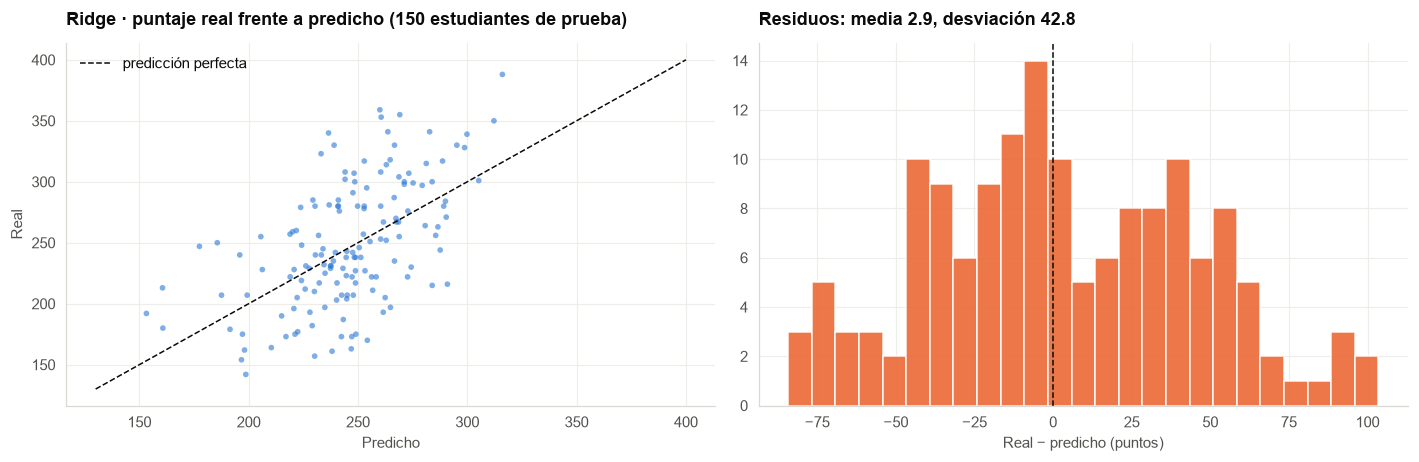

tramo,"(0, 200]","(200, 250]","(250, 300]","(300, 500]"
n,26.000,56.000,42.000,26.000
residuo medio,-45.900,-11.700,18.900,57.600
MAE,50.300,24.200,25.700,57.900


In [14]:
resultados_reg = {}
media = DummyRegressor(strategy="mean").fit(Xl_train, y_train)
resultados_reg["Media (ingenuo)"] = {p: evaluar_regresion(yy, media.predict(XX)) for p, XX, yy in [("train", Xl_train, y_train), ("val", Xl_val, y_val), ("test", Xl_test, y_test)]}

alphas = np.logspace(-1, 3, 17)
cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
mae_alpha = pd.Series({a: -cross_val_score(Ridge(alpha=a), Xl_train, y_train, cv=cv5, scoring="neg_mean_absolute_error").mean() for a in alphas})
ALPHA = float(mae_alpha.idxmin())
ridge = Ridge(alpha=ALPHA).fit(Xl_train, y_train)
resultados_reg["Ridge (referencia)"] = {p: evaluar_regresion(yy, ridge.predict(XX)) for p, XX, yy in [("train", Xl_train, y_train), ("val", Xl_val, y_val), ("test", Xl_test, y_test)]}

tabla_reg = pd.concat({m: pd.DataFrame(r).T for m, r in resultados_reg.items()}); tabla_reg.index.names = ["modelo", "parte"]
print(f"alpha elegido por validación cruzada: {ALPHA:g} (MAE cv {mae_alpha.min():.2f}; rango probado {alphas.min():g} a {alphas.max():g})")
display(tabla_reg.round(3))
mejora = 1 - tabla_reg.loc[("Ridge (referencia)", "test"), "MAE"] / tabla_reg.loc[("Media (ingenuo)", "test"), "MAE"]
print(f"Reducción del MAE en prueba frente a la media: {mejora * 100:.1f} % (meta del proyecto: al menos 15 %)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
pred = ridge.predict(Xl_test)
axes[0].scatter(pred, y_test, s=14, alpha=0.6, color=C_BASE, edgecolors="none")
axes[0].plot([130, 400], [130, 400], color=TINTA, linestyle="--", linewidth=1, label="predicción perfecta")
axes[0].set_title("Ridge · puntaje real frente a predicho (150 estudiantes de prueba)"); axes[0].set_xlabel("Predicho"); axes[0].set_ylabel("Real"); axes[0].legend(frameon=False)
resid = y_test - pred
axes[1].hist(resid, bins=25, color=C_ACCENT, alpha=0.9, edgecolor="white"); axes[1].axvline(0, color=TINTA, linestyle="--", linewidth=1)
axes[1].set_title(f"Residuos: media {resid.mean():.1f}, desviación {resid.std():.1f}"); axes[1].set_xlabel("Real − predicho (puntos)")
fig.tight_layout(); save_fig(fig, "baseline_regression"); plt.show()
sesgo = pd.DataFrame({"real": y_test, "pred": pred}).assign(tramo=lambda d: pd.cut(d["real"], [0, 200, 250, 300, 500]))
display(sesgo.groupby("tramo", observed=True).apply(lambda g: pd.Series({"n": len(g), "residuo medio": (g["real"] - g["pred"]).mean(), "MAE": (g["real"] - g["pred"]).abs().mean()})).round(1).T)

La validación cruzada selecciona alpha = 56, una regularización fuerte que resulta razonable con 70 columnas muy parecidas entre sí y solo 700 estudiantes para entrenar. En el grupo de prueba, Ridge obtiene un MAE de 35,0 puntos, sus predicciones se apartan 35 puntos de los resultados reales. El RMSE es 42,7 y el R² es 0,305, por lo que el modelo explica cerca del 30 % de las diferencias observadas entre estudiantes.

Como referencia, predecir siempre el puntaje promedio produce un error de 42,2 punto, Ridge reduce el error en 17,1 %, por encima de la meta inicial del 15 %.

El modelo rinde algo mejor en entrenamiento que en validación ya que el MAE es de 33,3 frente a 36,6 puntos, donde esta diferencia sugiere cierto sobreajuste, aunque también refleja la variación esperable al evaluar con un grupo de solo 150 estudiantes, por tal motivo, en la fase 3 los modelos se compararán mediante validación cruzada, en lugar de depender de una única partición pequeña.

El diagnóstico también revela una limitación propia del modelo lineal, ya que tiende a aplanar los extremos y casi todas sus predicciones quedan entre 150 y 320 puntos sobreestimando en unos 46 puntos a quienes obtienen menos de 200 y subestimando en unos 58 a quienes superan los 300.

### 8.2 Nivel de desempeño: clasificación al azar y regresión logística

La primera referencia es un clasificador que asigna los niveles al azar respetando que las tres clases son igual de frecuentes, con lo cual acierta más o menos una de cada tres veces. La segunda es una regresión logística, el modelo lineal más sencillo para clasificar, que calcula para cada estudiante la probabilidad de pertenecer a cada nivel y que también lleva una regularización elegida con validación cruzada. La métrica principal es el F1 macro y la matriz de confusión permite ver en qué se confunde el modelo, por ejemplo, cuántos estudiantes de nivel medio terminan clasificados como de nivel bajo.

C elegido por validación cruzada: 0.0001 (F1 macro cv 0.498)


exactitud  precisión macro  exhaustividad macro  F1 macro  AUC-ROC (ovr)
modelo                           parte                                                                          
Ingenuo (estratificado)          train      0.353            0.353                0.353     0.353          0.515
                                 val        0.293            0.294                0.294     0.294          0.470
                                 test       0.333            0.333                0.333     0.333          0.500
Regresión logística (referencia) train      0.531            0.540                0.531     0.532          0.701
                                 val        0.493            0.511                0.491     0.487          0.655
                                 test       0.480            0.509                0.480     0.482          0.664

Figura guardada: assets\images\data\baseline_classification.png


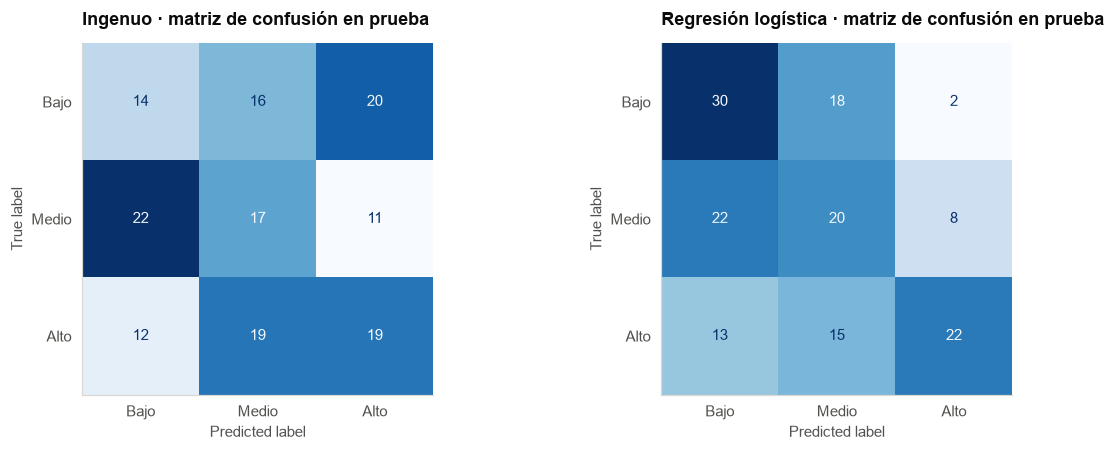

In [15]:
resultados_clf = {}
ingenuo = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE).fit(Xl_train, c_train)
resultados_clf["Ingenuo (estratificado)"] = {p: evaluar_clasificacion(cc, ingenuo.predict(XX), ingenuo.predict_proba(XX)) for p, XX, cc in [("train", Xl_train, c_train), ("val", Xl_val, c_val), ("test", Xl_test, c_test)]}

cv5s = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
Cs = np.logspace(-4, 1, 11)
f1_C = pd.Series({C: cross_val_score(LogisticRegression(C=C, max_iter=2000), Xl_train, c_train, cv=cv5s, scoring="f1_macro").mean() for C in Cs})
C_OPT = float(f1_C.idxmax())
logistica = LogisticRegression(C=C_OPT, max_iter=2000).fit(Xl_train, c_train)
resultados_clf["Regresión logística (referencia)"] = {p: evaluar_clasificacion(cc, logistica.predict(XX), logistica.predict_proba(XX)) for p, XX, cc in [("train", Xl_train, c_train), ("val", Xl_val, c_val), ("test", Xl_test, c_test)]}

tabla_clf = pd.concat({m: pd.DataFrame(r).T for m, r in resultados_clf.items()}); tabla_clf.index.names = ["modelo", "parte"]
print(f"C elegido por validación cruzada: {C_OPT:g} (F1 macro cv {f1_C.max():.3f})")
display(tabla_clf.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (nombre, modelo) in zip(axes, [("Ingenuo", ingenuo), ("Regresión logística", logistica)]):
    ConfusionMatrixDisplay(confusion_matrix(c_test, modelo.predict(Xl_test), labels=CLASES), display_labels=CLASES).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{nombre} · matriz de confusión en prueba"); ax.grid(False)
fig.tight_layout(); save_fig(fig, "baseline_classification"); plt.show()

Asignar los niveles al azar da un F1 macro de 0,333 y un AUC de 0,500, que es justo lo esperado con tres clases del mismo tamaño, mientras que la regresión logística alcanza en prueba un F1 macro de 0,482, una exactitud de 0,480 y un AUC-ROC de 0,664, unos 15 puntos de F1 por encima del azar. La validación cruzada escogió la regularización más fuerte entre las que se probaron (`C` igual a 0,0001), una señal de que con 700 estudiantes cualquier libertad adicional se convierte en ruido, aunque entre las opciones más fuertes el F1 cambia menos de dos centésimas.

La matriz de confusión es lo más revelador de esta parte, porque muestra que el modelo distingue bien los extremos, ya que acierta con 30 de los 50 estudiantes de nivel bajo y con 22 de los 50 de nivel alto y casi nunca confunde a uno bajo con uno alto, mientras que el nivel medio es el difícil, con apenas 20 aciertos de 50, no obstante, tiene sentido que sea así, pues las fronteras de 222 y 273 puntos separan a estudiantes casi iguales y el contexto familiar o escolar no alcanza a diferenciar a uno de 220 puntos de otro de 225, así que la meta para la fase 3 es superar un F1 de 0,48 y sobre todo, mejorar en el nivel medio.

## 9. Lo que se guarda para la fase 3

Se guardan el dataset limpio, que incluye las variables nuevas y por aparte, los puntajes por área para el agrupamiento de estudiantes, la división en tres grupos, la lista de columnas, los cortes que definen los niveles de desempeño, los dos preprocesadores y los dos modelos de referencia con sus métricas. El cuaderno 03 carga estos archivos y si no los encuentra, como ocurre en una sesión nueva de Colab, los reconstruye con código y obtiene exactamente lo mismo.

In [16]:
df_final = df.join(areas)
df_final.to_parquet(PROCESSED_DIR / "saber11_fase2.parquet")
particion.to_frame().to_parquet(PROCESSED_DIR / "particion.parquet")
json.dump({"NUM_COLS": NUM_COLS, "BIN_COLS": BIN_COLS, "NOM_COLS": NOM_COLS, "AREA_COLS": AREA_COLS, "TARGET": TARGET,
           "CLASES": CLASES, "CORTES_NIVEL": CORTES_NIVEL, "P99_EDAD": P99, "ALPHA_RIDGE": ALPHA, "C_LOGISTICA": C_OPT},
          open(PROCESSED_DIR / "columnas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
joblib.dump(ridge, MODELS_DIR / "baseline_ridge.joblib"); joblib.dump(logistica, MODELS_DIR / "baseline_logistica.joblib")
tabla_reg.to_csv(PROCESSED_DIR / "metricas_fase2_regresion.csv"); tabla_clf.to_csv(PROCESSED_DIR / "metricas_fase2_clasificacion.csv")
pd.DataFrame({"y_real": y_test, "nivel_real": c_test, "pred_ridge": ridge.predict(Xl_test), "pred_logistica": logistica.predict(Xl_test)}, index=y_test.index).to_parquet(PROCESSED_DIR / "predicciones_fase2.parquet")
print("Guardado en data/processed/:", sorted(p.name for p in PROCESSED_DIR.iterdir() if p.name != ".gitkeep"))
print("Guardado en models/:", sorted(p.name for p in MODELS_DIR.iterdir() if p.name != ".gitkeep"))

Guardado en data/processed/: ['clustering.json', 'clusters.parquet', 'columnas.json', 'diccionario_datos.csv', 'frecuencias_alta_cardinalidad.csv', 'frecuencias_cualitativas.csv', 'importancias.csv', 'metricas_fase2_clasificacion.csv', 'metricas_fase2_regresion.csv', 'metricas_fase3_clasificacion.csv', 'metricas_fase3_regresion.csv', 'particion.parquet', 'predicciones_fase2.parquet', 'predicciones_fase3.parquet', 'resumen_clasificacion.csv', 'resumen_regresion.csv', 'saber11_fase2.parquet']
Guardado en models/: ['baseline_logistica.joblib', 'baseline_ridge.joblib', 'clf_knn.joblib', 'clf_random_forest.joblib', 'clf_svm.joblib', 'clustering.joblib', 'mejor_clasificacion.joblib', 'mejor_clasificacion_info.joblib', 'mejor_regresion.joblib', 'mejor_regresion_info.joblib', 'mlp_regresion.json', 'mlp_regresion.pt', 'prep_arboles.joblib', 'prep_lineal.joblib', 'reg_elasticnet.joblib', 'reg_gradient_boosting.joblib', 'reg_lasso.joblib', 'reg_random_forest.joblib']


Queda guardado todo lo necesario para la siguiente fase, el dataset limpio, la división en tres grupos, la lista de columnas con los cortes de los niveles, los dos preprocesadores, los dos modelos de referencia, sus métricas y sus predicciones sobre el grupo de prueba, de modo que el cuaderno 03 arranca desde aquí.

## 10. Conclusiones

* Los datos quedaron listos para modelar, con 1.000 estudiantes y 24 variables que describen al estudiante, su hogar y su colegio antes de presentar la prueba, luego de retirar los puntajes por área, que habrían generado fuga de información, junto con los códigos, los nombres y las columnas sin variación.

* Los datos faltantes se trataron como información y no como basura, porque quienes no responden el cuestionario obtienen menores puntajes, así que se les asignó una opción propia, *No respondió*, y una columna que los identifica, además se comprobó con datos que rellenar con la mediana funciona tan bien como métodos más complejos, mientras que eliminar filas da peores resultados y dejaría por fuera al 18 % de la muestra.

* Los valores extremos se conservaron, ya que los puntajes excepcionales son reales y en el caso de la edad de los adultos se aplicó un recorte en 35 años para que no desequilibre los modelos, sin retirar a nadie. También se crearon variables con sentido, como el hacinamiento, la extraedad, el cuestionario incompleto, la educación desconocida de los padres y el cruce entre naturaleza y zona del colegio y se agruparon los estratos altos y los departamentos para que cada grupo tuviera suficientes estudiantes.

* La evaluación quedó protegida contra la fuga de información, pues los estudiantes se dividieron en grupos de 700, 150 y 150 con la misma proporción de niveles y todas las transformaciones se aprendieron únicamente del grupo de entrenamiento, algo que se verificó de forma explícita.

* Con estos resultados queda establecida la línea base para comparar los modelos de la fase 3, por un lado, para predecir el puntaje, la regresión lineal se equivoca en promedio por 35 puntos y explica el 30 % de las diferencias entre estudiantes, esto representa una mejora del 17 % frente a predecir siempre el promedio, por el otro, ara clasificar el nivel de desempeño, la regresión logística alcanza un F1 macro de 0,48, frente a 0,33 de una referencia basada en el azar. Ambos modelos comparten limitaciones, aplanan los valores extremos y confunden con frecuencia el nivel medio, por consiguiente, la fase 3 buscará modelos que mejoren esos resultados y manejen mejor esos casos.